### Phase 2 (Data Understanding)

#### Content of the data

The dataset contains real world used cars details. It consists of 66 features of cars (columns) and 3000060 cars (rows). The dataset is a single file in CSV format.

In [22]:
print('Rows: ' + str(df.shape[0]))    # rows
print('Columns: ' + str(df.shape[1])) # columns

Rows: 3000040
Columns: 66


In [12]:
df.columns  # list of columns

Index(['vin', 'back_legroom', 'bed', 'bed_height', 'bed_length', 'body_type',
       'cabin', 'city', 'city_fuel_economy', 'combine_fuel_economy',
       'daysonmarket', 'dealer_zip', 'description', 'engine_cylinders',
       'engine_displacement', 'engine_type', 'exterior_color', 'fleet',
       'frame_damaged', 'franchise_dealer', 'franchise_make', 'front_legroom',
       'fuel_tank_volume', 'fuel_type', 'has_accidents', 'height',
       'highway_fuel_economy', 'horsepower', 'interior_color', 'isCab',
       'is_certified', 'is_cpo', 'is_new', 'is_oemcpo', 'latitude', 'length',
       'listed_date', 'listing_color', 'listing_id', 'longitude',
       'main_picture_url', 'major_options', 'make_name', 'maximum_seating',
       'mileage', 'model_name', 'owner_count', 'power', 'price', 'salvage',
       'savings_amount', 'seller_rating', 'sp_id', 'sp_name', 'theft_title',
       'torque', 'transmission', 'transmission_display', 'trimId', 'trim_name',
       'vehicle_damage_category', 'whe

In [6]:
df.describe().apply(lambda s: s.apply('{0:.5f}'.format))    # statistics of numeric values

,city_fuel_economy,combine_fuel_economy,daysonmarket,engine_displacement,highway_fuel_economy,horsepower,is_certified,latitude,listing_id,longitude,mileage,owner_count,price,savings_amount,seller_rating,sp_id,vehicle_damage_category,year
count,2508755.00000,0.00000,3000040.00000,2827654.00000,2508755.00000,2827654.00000,0.00000,3000040.00000,3000040.00000,3000040.00000,2855653.00000,1483027.00000,3000040.00000,3000040.00000,2959168.00000,2999944.00000,0.00000,3000040.00000
mean,22.69325,nan,76.05973,2968.48769,29.47337,247.99571,nan,36.98414,275498673.82553,-90.64224,31146.89974,1.53264,29933.36690,550.97681,4.27041,233522.40599,nan,2017.72832
std,8.80702,nan,108.88385,1348.90451,7.76925,90.46639,nan,4.99682,8894122.67590,13.90589,74586.74520,0.92029,19566.16978,1079.44770,0.51330,132322.07095,nan,4.17870
min,7.00000,nan,0.00000,700.00000,10.00000,55.00000,nan,18.34670,19946203.00000,-157.92800,0.00000,1.00000,165.00000,0.00000,1.00000,41593.00000,nan,1915.00000
25%,18.00000,nan,14.00000,2000.00000,25.00000,175.00000,nan,33.50920,274579410.50000,-97.08820,6.00000,1.00000,18451.00000,0.00000,4.00000,63375.00000,nan,2017.00000
50%,21.00000,nan,35.00000,2500.00000,29.00000,244.00000,nan,37.84710,278545307.00000,-87.24950,8267.00000,1.00000,26477.00000,0.00000,4.34146,281627.00000,nan,2020.00000
75%,26.00000,nan,82.00000,3600.00000,33.00000,300.00000,nan,41.00620,280455336.25000,-80.45490,43662.00000,2.00000,38220.00000,785.00000,4.60526,336614.00000,nan,2020.00000
max,127.00000,nan,3599.00000,8400.00000,127.00000,1001.00000,nan,61.20310,282022171.00000,-66.07850,99999988.00000,19.00000,3299995.00000,147414.00000,5.00000,440951.00000,nan,2021.00000


#### Initial data analysis and data quality

There is a lot of missing values in the dataset. Columns 'is_certified', 'combine_fuel_economy' and 'vehicle_damage_category' is missing in all 3000040 cars. 
There is 17 columns where there are no missing values (such as: year, price, city, listing_date, listing_id, model_name, make_name). Few columns, such as 'milage' and 'fuel_type', have some missing values which needs to be taken into consideration.

In [16]:
print('Total sum of missing values: ' + str(df.isna().sum().sum().item()))   # total sum of missing values

Total sum of missing values: 42208456


In [24]:
print('Sum of missing values by column, sorted high to low, first 20:')
df.isna().sum().sort_values(ascending=False).head(20)   # sum of missing values by column, sorted high to low, first 20

Sum of missing values by column, sorted high to low, first 20:


is_certified               3000040
combine_fuel_economy       3000040
vehicle_damage_category    3000040
bed                        2980472
cabin                      2936507
is_oemcpo                  2864678
is_cpo                     2817142
bed_length                 2570942
bed_height                 2570942
owner_count                1517013
salvage                    1426595
theft_title                1426595
frame_damaged              1426595
fleet                      1426595
has_accidents              1426595
isCab                      1426595
franchise_make              572635
torque                      517793
city_fuel_economy           491285
highway_fuel_economy        491285
dtype: int64

In [25]:
print('Sum of missing values by column, sorted low to high, first 20:')
df.isna().sum().sort_values(ascending=True).head(20)    # sum of missing values by column, sorted low to high, first 20

Sum of missing values by column, sorted low to high, first 20:


vin                     0
city                    0
daysonmarket            0
dealer_zip              0
franchise_dealer        0
price                   0
sp_name                 0
savings_amount          0
make_name               0
model_name              0
longitude               0
listing_id              0
listed_date             0
listing_color           0
latitude                0
is_new                  0
year                    0
sp_id                  96
body_type           13543
seller_rating       40872
dtype: int64

All car prices in the dataset are valid. None of the cars are set at zero or negative prices.

In [27]:
print('Sum of rows where price is zero or less: ' + str((df['price'] <= 0).sum()))  # sum of rows where price is 0 or less

Sum of rows where price is zero or less: 0


The dataset contains a fair amount of cars that have a zero mileage. For used cars, it doesn't make sense.

In [29]:
print("Sum of rows where mileage is zero:", str((df['mileage'] == 0).sum()))    # sum of rows where mileage is 0

Sum of rows where mileage is zero: 256899


Correlation shows which numeric features might affect price.

In [31]:
numeric = df.select_dtypes(include=['int64', 'float64']).columns
print(df[numeric].corr()['price'].sort_values(ascending=False))

price                   1.000000
horsepower              0.605404
engine_displacement     0.375494
year                    0.355366
seller_rating           0.067230
daysonmarket            0.063288
savings_amount         -0.004081
latitude               -0.024897
longitude              -0.026925
listing_id             -0.058598
sp_id                  -0.121276
city_fuel_economy      -0.177619
owner_count            -0.230602
highway_fuel_economy   -0.255430
mileage                -0.274082
Name: price, dtype: float64


'Horsepower', 'engine_displacement' and 'year' correlate positively with price while 'mileage', 'highway_fuel_economy' and 'owner_count' correlate negatively with price.

#### Visualization

Visualization can be done with Python libraries such as Mathplotlib and Seaborn. Different sorts of graphs can be used, such as heatmaps, histograms and scatterplots.

Here is a full correlation matrix as a heatmap.

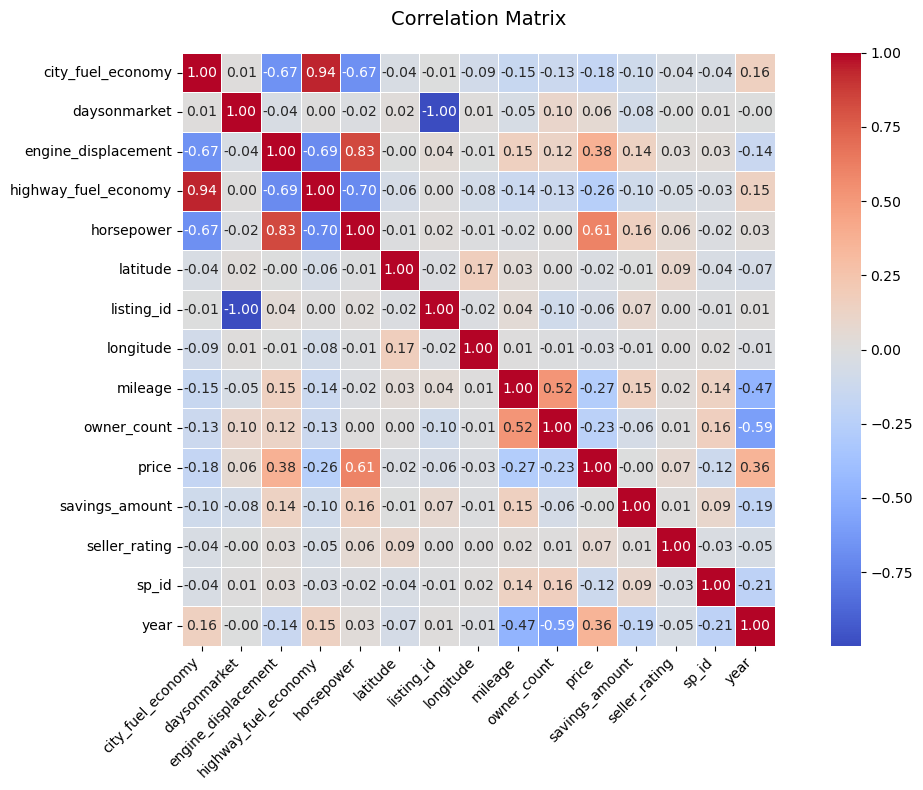

In [33]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, square=True )
plt.title("Correlation Matrix", fontsize=14, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

A histogram of the distribution of car prices shows that most cars cost between $10 000 and $30 000. The top 0.5% most expensive cars are excluded for a clearer graph.

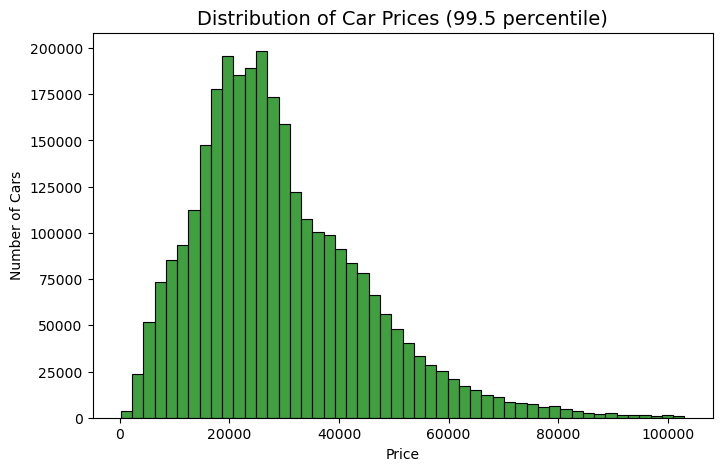

In [34]:
price_limit = df['price'].quantile(0.995)

plt.figure(figsize=(8,5))
sns.histplot(df['price'][df['price'] <= price_limit], bins=50, color='green')
plt.title("Distribution of Car Prices (99.5 percentile)", fontsize=14)
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.show()

#### Data grouping

The data can be grouped in many ways. For data analysis, useful groups include mileage groups (0-10k, 20-40k...), fuel type, transmission type, manifacturer or city.